**Lab 5-Tasks**  
**Course: ANN** 

**Khair ul wara Hussain**
**Student Id: FA23-BAI-022**

### Lab Task 1: Loading the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)

# Breast Cancer Wisconsin (Diagnostic) dataset from the UCI repository (bundled with scikit-learn)
raw = load_breast_cancer(as_frame=True)
df = raw.frame
df['diagnosis'] = df['target'].map({0: 'malignant', 1: 'benign'})

print("Dataset shape:", df.shape)
print("Number of features:", len(raw.feature_names))
print("Classes:", [str(c) for c in raw.target_names])
print("Missing values:", int(df.isnull().sum().sum()))
print()
print(df['diagnosis'].value_counts())

Dataset shape: (569, 32)
Number of features: 30
Classes: ['malignant', 'benign']
Missing values: 0

diagnosis
benign       357
malignant    212
Name: count, dtype: int64


In [2]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


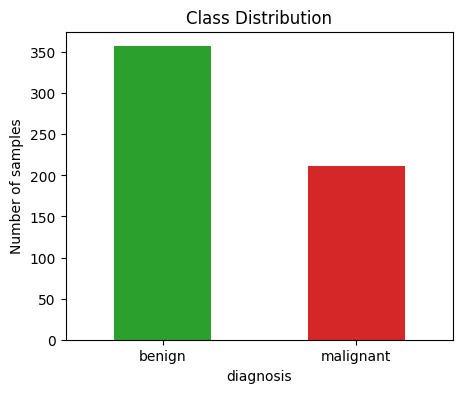

In [3]:
plt.figure(figsize=(5,4))
df['diagnosis'].value_counts().plot(kind='bar', color=['tab:green', 'tab:red'])
plt.title('Class Distribution')
plt.ylabel('Number of samples')
plt.xticks(rotation=0)
plt.show()

### Lab Task 2: Data Preprocessing

In [4]:
X = raw.data.values
y = raw.target.values

# Stratified split keeps the class ratio the same in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# LVQ uses Euclidean distance, so all features must be on the same scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit only on training data
X_test = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))
print("Train mean (first 3 features):", X_train.mean(axis=0)[:3].round(4))
print("Train std (first 3 features):", X_train.std(axis=0)[:3].round(4))

Training set: (455, 30)
Test set: (114, 30)
Train class counts: [170 285]
Test class counts: [42 72]
Train mean (first 3 features): [-0.  0. -0.]
Train std (first 3 features): [1. 1. 1.]


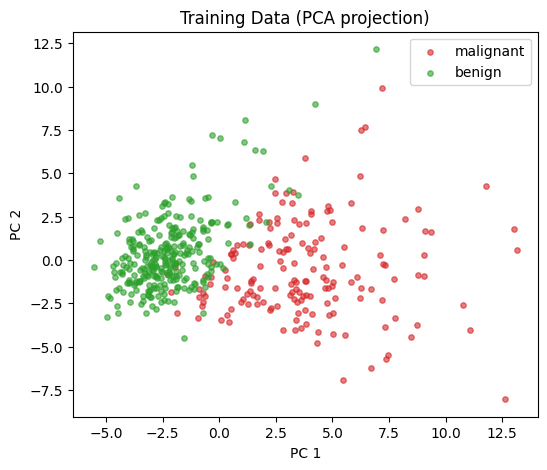

Variance explained by 2 components: 63.36%


In [5]:
# Reduce to 2 components only for visualization
pca = PCA(n_components=2)
train_2d = pca.fit_transform(X_train)

plt.figure(figsize=(6,5))
for label, name, color in [(0, 'malignant', 'tab:red'), (1, 'benign', 'tab:green')]:
    plt.scatter(train_2d[y_train == label, 0], train_2d[y_train == label, 1], s=15, c=color, alpha=0.6, label=name)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Training Data (PCA projection)')
plt.legend()
plt.show()

print("Variance explained by 2 components: {:.2f}%".format(pca.explained_variance_ratio_.sum() * 100))

### Lab Task 3: LVQ Implementation

In [6]:
class LVQ:
    def __init__(self, prototypes_per_class=3, learning_rate=0.1, epochs=50, random_state=42):
        self.k = prototypes_per_class
        self.alpha0 = learning_rate
        self.epochs = epochs
        self.rng = np.random.RandomState(random_state)

    def winner(self, x):
        # Index of the prototype with the smallest Euclidean distance to x
        distances = np.sqrt(np.sum((self.weights - x) ** 2, axis=1))
        return np.argmin(distances)

    def update(self, x, j, actual, alpha):
        # Move the winner towards x if the class matches, away from x if it does not
        if self.proto_labels[j] == actual:
            self.weights[j] += alpha * (x - self.weights[j])
        else:
            self.weights[j] -= alpha * (x - self.weights[j])

    def fit(self, X, y):
        classes = np.unique(y)
        init_ids = []
        # Initialise k prototypes for every class from random training samples
        for c in classes:
            ids = self.rng.choice(np.where(y == c)[0], self.k, replace=False)
            init_ids.extend(ids)
        init_ids = np.array(init_ids)
        self.weights = X[init_ids].astype(float).copy()
        self.proto_labels = y[init_ids].copy()

        # Samples used for initialisation are not used in training
        mask = np.ones(len(X), dtype=bool)
        mask[init_ids] = False
        X_tr, y_tr = X[mask], y[mask]

        self.history = []
        for epoch in range(self.epochs):
            alpha = self.alpha0 * (1 - epoch / self.epochs)   # decaying learning rate
            for i in self.rng.permutation(len(X_tr)):
                j = self.winner(X_tr[i])
                self.update(X_tr[i], j, y_tr[i], alpha)
            self.history.append(accuracy_score(y_tr, self.predict(X_tr)))
        return self

    def predict(self, X):
        return np.array([self.proto_labels[self.winner(x)] for x in X])

### Lab Task 4: Training the LVQ Model

Number of prototypes: 6
Prototype labels: [0 0 0 1 1 1]
Accuracy after epoch 1: 0.9443
Accuracy after final epoch: 0.9465


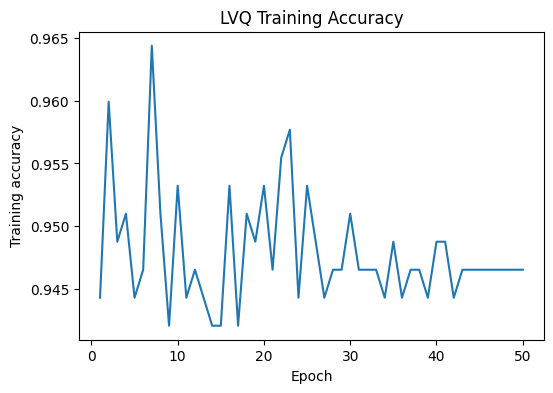

In [7]:
lvq = LVQ(prototypes_per_class=3, learning_rate=0.1, epochs=50)
lvq.fit(X_train, y_train)

print("Number of prototypes:", len(lvq.weights))
print("Prototype labels:", lvq.proto_labels)
print("Accuracy after epoch 1:", round(lvq.history[0], 4))
print("Accuracy after final epoch:", round(lvq.history[-1], 4))

plt.figure(figsize=(6,4))
plt.plot(range(1, len(lvq.history) + 1), lvq.history)
plt.xlabel('Epoch')
plt.ylabel('Training accuracy')
plt.title('LVQ Training Accuracy')
plt.show()

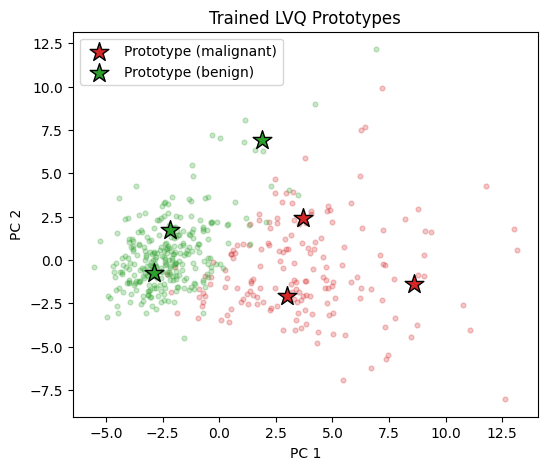

In [8]:
# Prototypes projected on the same 2D view
proto_2d = pca.transform(lvq.weights)

plt.figure(figsize=(6,5))
for label, color in [(0, 'tab:red'), (1, 'tab:green')]:
    plt.scatter(train_2d[y_train == label, 0], train_2d[y_train == label, 1], s=12, c=color, alpha=0.25)
    plt.scatter(proto_2d[lvq.proto_labels == label, 0], proto_2d[lvq.proto_labels == label, 1],
                s=200, c=color, marker='*', edgecolors='black', label='Prototype (' + raw.target_names[label] + ')')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Trained LVQ Prototypes')
plt.legend()
plt.show()

### Lab Task 5: Model Evaluation

In [9]:
y_pred = lvq.predict(X_test)

print("Test accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
print()
print(classification_report(y_test, y_pred, target_names=raw.target_names))

Test accuracy: 0.9298

              precision    recall  f1-score   support

   malignant       0.93      0.88      0.90        42
      benign       0.93      0.96      0.95        72

    accuracy                           0.93       114
   macro avg       0.93      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



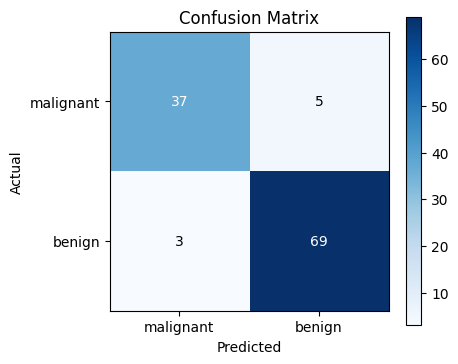

Correct predictions: 106 out of 114


In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(4.5,4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], raw.target_names)
plt.yticks([0, 1], raw.target_names)
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("Correct predictions:", cm.trace(), "out of", cm.sum())

### Lab Task 6: Hyperparameter Experiments

Fit set: (364, 30)  Validation set: (91, 30)


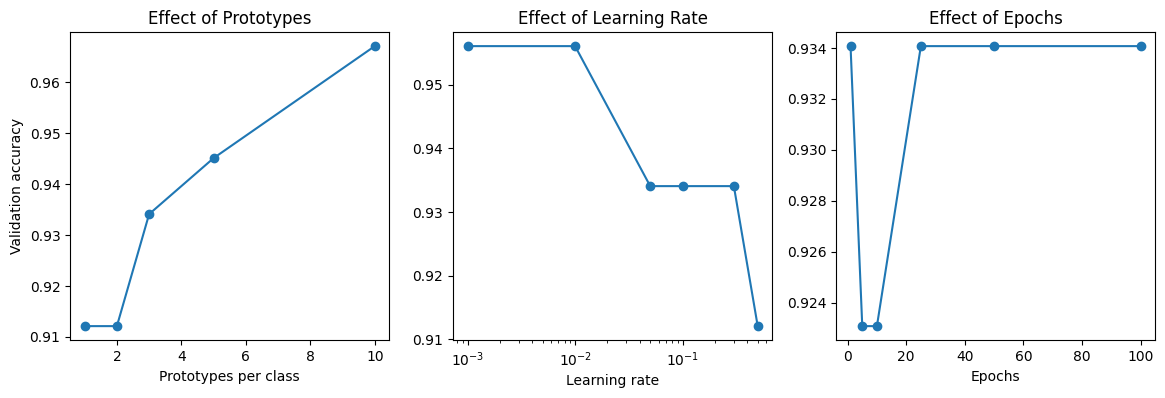

In [11]:
# Hyperparameters are compared on a validation set taken from the training data,
# so the test set stays untouched until the final evaluation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=1, stratify=y_train)
print("Fit set:", X_fit.shape, " Validation set:", X_val.shape)

results = []

plt.figure(figsize=(14,4))

# Experiment 1: number of prototypes per class
protos = [1, 2, 3, 5, 10]
accs = []
for k in protos:
    m = LVQ(prototypes_per_class=k, learning_rate=0.1, epochs=50).fit(X_fit, y_fit)
    accs.append(accuracy_score(y_val, m.predict(X_val)))
    results.append(('Prototypes per class', k, accs[-1]))
plt.subplot(1, 3, 1)
plt.plot(protos, accs, marker='o')
plt.xlabel('Prototypes per class')
plt.ylabel('Validation accuracy')
plt.title('Effect of Prototypes')

# Experiment 2: initial learning rate
rates = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5]
accs = []
for lr in rates:
    m = LVQ(prototypes_per_class=3, learning_rate=lr, epochs=50).fit(X_fit, y_fit)
    accs.append(accuracy_score(y_val, m.predict(X_val)))
    results.append(('Learning rate', lr, accs[-1]))
plt.subplot(1, 3, 2)
plt.semilogx(rates, accs, marker='o')
plt.xlabel('Learning rate')
plt.title('Effect of Learning Rate')

# Experiment 3: number of epochs
epoch_list = [1, 5, 10, 25, 50, 100]
accs = []
for e in epoch_list:
    m = LVQ(prototypes_per_class=3, learning_rate=0.1, epochs=e).fit(X_fit, y_fit)
    accs.append(accuracy_score(y_val, m.predict(X_val)))
    results.append(('Epochs', e, accs[-1]))
plt.subplot(1, 3, 3)
plt.plot(epoch_list, accs, marker='o')
plt.xlabel('Epochs')
plt.title('Effect of Epochs')
plt.show()

In [12]:
print(f"{'Setting':<24}{'Value':<10}{'Validation Accuracy'}")
for name, value, acc in results:
    print(f"{name:<24}{value:<10}{acc:.4f}")

Setting                 Value     Validation Accuracy
Prototypes per class    1         0.9121
Prototypes per class    2         0.9121
Prototypes per class    3         0.9341
Prototypes per class    5         0.9451
Prototypes per class    10        0.9670
Learning rate           0.001     0.9560
Learning rate           0.01      0.9560
Learning rate           0.05      0.9341
Learning rate           0.1       0.9341
Learning rate           0.3       0.9341
Learning rate           0.5       0.9121
Epochs                  1         0.9341
Epochs                  5         0.9231
Epochs                  10        0.9231
Epochs                  25        0.9341
Epochs                  50        0.9341
Epochs                  100       0.9341


In [13]:
# Small grid search over all three hyperparameters together (scored on the validation set)
grid = []
for k in [1, 3, 5, 10]:
    for lr in [0.01, 0.1, 0.3]:
        for e in [10, 50]:
            m = LVQ(prototypes_per_class=k, learning_rate=lr, epochs=e).fit(X_fit, y_fit)
            grid.append((k, lr, e, accuracy_score(y_val, m.predict(X_val))))

grid_df = pd.DataFrame(grid, columns=['prototypes', 'learning_rate', 'epochs', 'val_accuracy'])
grid_df = grid_df.sort_values('val_accuracy', ascending=False).reset_index(drop=True)
print("Configurations tried:", len(grid_df))
print()
print(grid_df.head(5).to_string())

Configurations tried: 24

   prototypes  learning_rate  epochs  val_accuracy
0           3           0.01      10      0.978022
1          10           0.10      50      0.967033
2          10           0.10      10      0.967033
3          10           0.30      50      0.967033
4          10           0.30      10      0.956044


In [14]:
best = grid_df.iloc[0]
best_k, best_lr, best_ep = int(best['prototypes']), float(best['learning_rate']), int(best['epochs'])
print("Chosen prototypes per class:", best_k)
print("Chosen learning rate:", best_lr)
print("Chosen epochs:", best_ep)

# Retrain on the full training set and evaluate once on the test set
tuned = LVQ(prototypes_per_class=best_k, learning_rate=best_lr, epochs=best_ep).fit(X_train, y_train)
tuned_acc = accuracy_score(y_test, tuned.predict(X_test))
base_acc = accuracy_score(y_test, lvq.predict(X_test))

print()
print("Test accuracy (initial model):", round(base_acc, 4))
print("Test accuracy (tuned model):  ", round(tuned_acc, 4))

Chosen prototypes per class: 3
Chosen learning rate: 0.01
Chosen epochs: 10

Test accuracy (initial model): 0.9298
Test accuracy (tuned model):   0.9298


### Lab Task 7: Stability Check

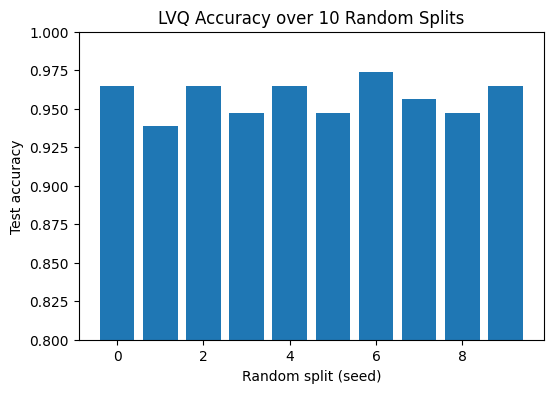

Mean accuracy: 0.957
Std deviation: 0.0107
Min / Max: 0.9386 / 0.9737


In [15]:
# Repeat the whole pipeline (split, scaling, training) with 10 different random splits
split_accs = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    sc = StandardScaler()
    Xa = sc.fit_transform(Xa)
    Xb = sc.transform(Xb)
    m = LVQ(prototypes_per_class=3, learning_rate=0.1, epochs=50, random_state=s).fit(Xa, ya)
    split_accs.append(accuracy_score(yb, m.predict(Xb)))

plt.figure(figsize=(6,4))
plt.bar(range(10), split_accs)
plt.ylim(0.8, 1.0)
plt.xlabel('Random split (seed)')
plt.ylabel('Test accuracy')
plt.title('LVQ Accuracy over 10 Random Splits')
plt.show()

print("Mean accuracy:", round(np.mean(split_accs), 4))
print("Std deviation:", round(np.std(split_accs), 4))
print("Min / Max:", round(min(split_accs), 4), "/", round(max(split_accs), 4))

### Report Summary

**Data preprocessing**
- Dataset: Breast Cancer Wisconsin (Diagnostic) from the UCI repository, 569 samples, 30 numeric features, 2 classes (357 benign, 212 malignant). There were no missing values.
- Stratified 80/20 split (455 training, 114 test samples) so both sets keep the same class ratio.
- StandardScaler fitted on the training set only and applied to the test set, because LVQ depends on Euclidean distance and the raw features have very different ranges.

**Model architecture and hyperparameters**
- LVQ1 implemented from scratch with NumPy: an input layer of 30 features and an output layer of prototype vectors, each prototype labelled with a class.
- Initial setting: 3 prototypes per class (6 in total), learning rate 0.1 decreasing linearly to 0, and 50 epochs. Prototypes start from random training samples of their own class, and those samples are left out of training (as in the lab description). Several prototypes per class are used because a class can cover more than one region of the feature space.
- A decaying learning rate lets the prototypes move quickly at first and settle later.

**Training and evaluation**
- Update rule: the closest prototype moves towards the sample when its label matches and away from it when it does not.
- Training accuracy was 0.9443 after epoch 1 and 0.9465 after epoch 50. Test accuracy was 0.9298 (106 of 114 correct), with recall of 0.88 for malignant and 0.96 for benign.
- Experiments on a validation split: accuracy rose from 0.912 with 1 prototype per class to 0.967 with 10; a learning rate of 0.5 gave the lowest accuracy (0.912); the number of epochs made little difference after the first epoch.
- The grid search chose 3 prototypes, learning rate 0.01 and 10 epochs (validation accuracy 0.978), but its test accuracy was 0.9298, the same as the initial model, so the gain on the validation set did not carry over to unseen data.

**Observations**
- Over 10 different random splits, mean test accuracy was 0.957 with a standard deviation of 0.011 (range 0.939 to 0.974), so the 0.9298 on the first split is on the lower side and differences of a point or two between settings are within normal variation.
- Malignant samples are missed more often than benign ones (8 errors in total, 5 of them malignant samples predicted as benign), which would matter in a real screening setting.
- Training accuracy is higher than test accuracy but the gap is small, so the model is not overfitting.